<a href="https://colab.research.google.com/github/arxsyy/PCVK_Ganjil_2026/blob/main/Week9_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


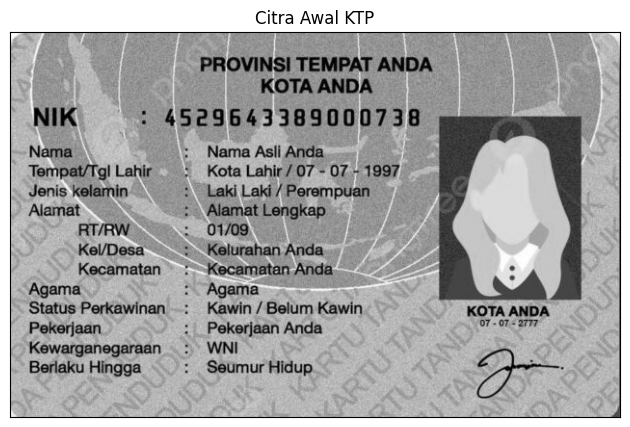

In [3]:
# Nomor 2. Import Library
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, morphology
from skimage.morphology import skeletonize
from skimage.util import img_as_float

# Membaca citra KTP
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/ktp.jpg', 0)

# Membuat citra biner
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(10, 5))
plt.imshow(img, cmap='gray')
plt.title('Citra Awal KTP')
plt.xticks([])
plt.yticks([])
plt.show()

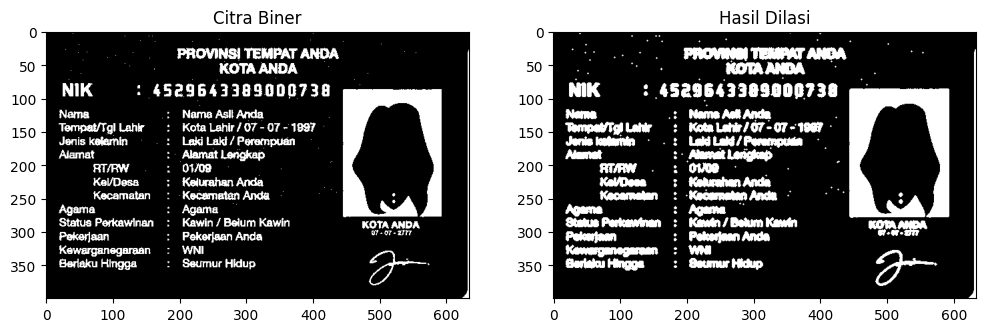

In [4]:
# Nomor 3. Dilasi Tanpa Library Morphology
def dilasi_citra(F, kernel):
    p, q = F.shape
    h, w = kernel.shape
    pad_h, pad_w = h // 2, w // 2
    padded = np.pad(F, ((pad_h, pad_h), (pad_w, pad_w)))
    imgD = np.zeros_like(F)

    for i in range(p):
        for j in range(q):
            temp = padded[i:i+h, j:j+w]
            imgD[i, j] = np.max(temp * kernel)

    return imgD

SED = np.array([[0, 1, 0],
                [1, 1, 1],
                [0, 1, 0]], dtype=np.uint8)

imgD = dilasi_citra(thresh, SED)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(122), plt.imshow(imgD, cmap='gray'), plt.title('Hasil Dilasi')
plt.show()

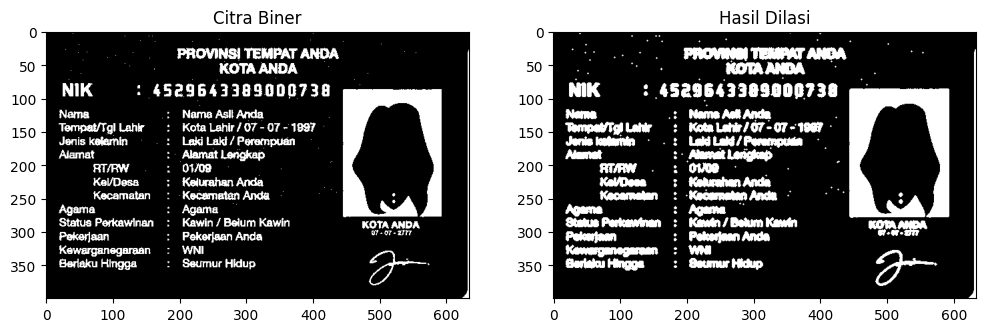

In [5]:
# Nomor 4. Dilasi Menggunakan Library Morphology OpenCV
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
dilasi = cv2.dilate(thresh, kernel, iterations=1)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(122), plt.imshow(dilasi, cmap='gray'), plt.title('Hasil Dilasi')
plt.show()

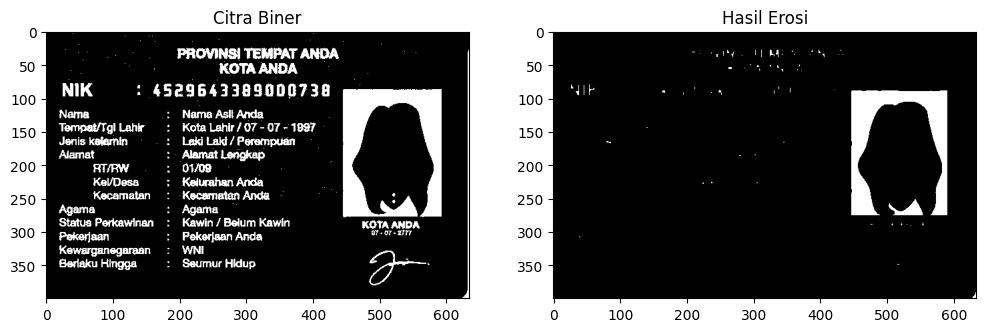

In [6]:
# Nomor 5. Erosi Tanpa Library Morphology
def erosi_citra(F, kernel):
    p, q = F.shape
    h, w = kernel.shape
    pad_h, pad_w = h // 2, w // 2
    padded = np.pad(F, ((pad_h, pad_h), (pad_w, pad_w)),
                    constant_values=255)
    imgE = np.zeros_like(F)

    for i in range(p):
        for j in range(q):
            temp = padded[i:i+h, j:j+w]
            imgE[i, j] = np.min(temp[kernel == 1])

    return imgE

SE = np.ones((5, 5), dtype=np.uint8)
imgE = erosi_citra(thresh, SE)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(122), plt.imshow(imgE, cmap='gray'), plt.title('Hasil Erosi')
plt.show()

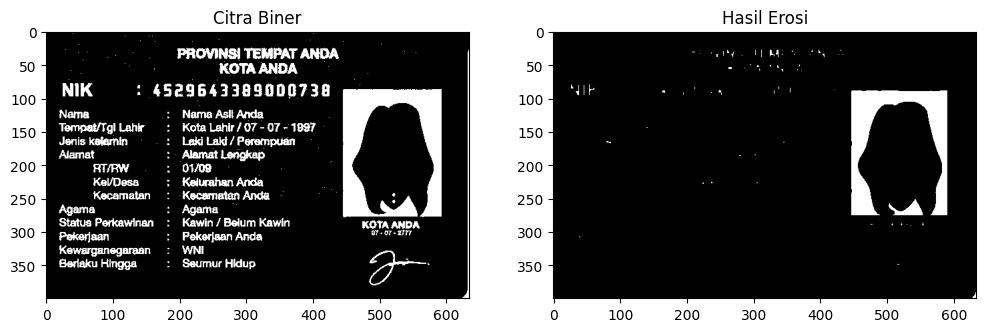

In [7]:
# Nomor 6. Erosi Menggunakan Library Morphology OpenCV
kernel = np.ones((5, 5), dtype=np.uint8)
erosion = cv2.erode(thresh, kernel, iterations=1)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(122), plt.imshow(erosion, cmap='gray'), plt.title('Hasil Erosi')
plt.show()

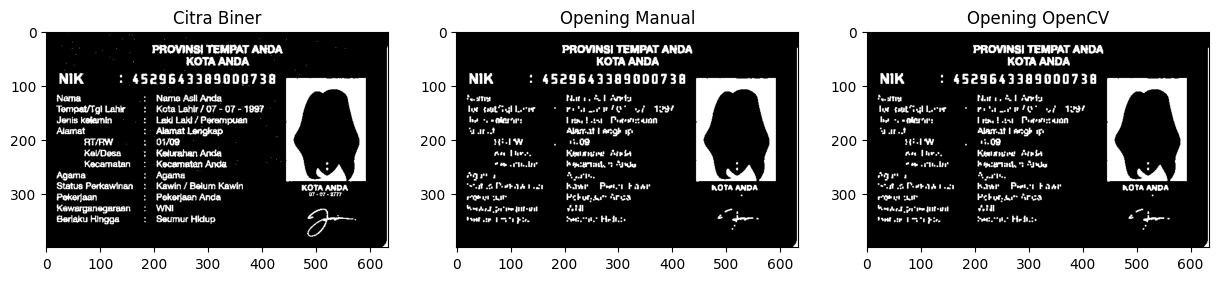

In [8]:
# Nomor 7. Opening Tanpa dan Dengan Library Morphology
SE = np.ones((3, 3), dtype=np.uint8)
opening_manual = dilasi_citra(erosi_citra(thresh, SE), SE)

kernel = np.ones((3, 3), dtype=np.uint8)
opening_lib = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(132), plt.imshow(opening_manual, cmap='gray'), plt.title('Opening Manual')
plt.subplot(133), plt.imshow(opening_lib, cmap='gray'), plt.title('Opening OpenCV')
plt.show()

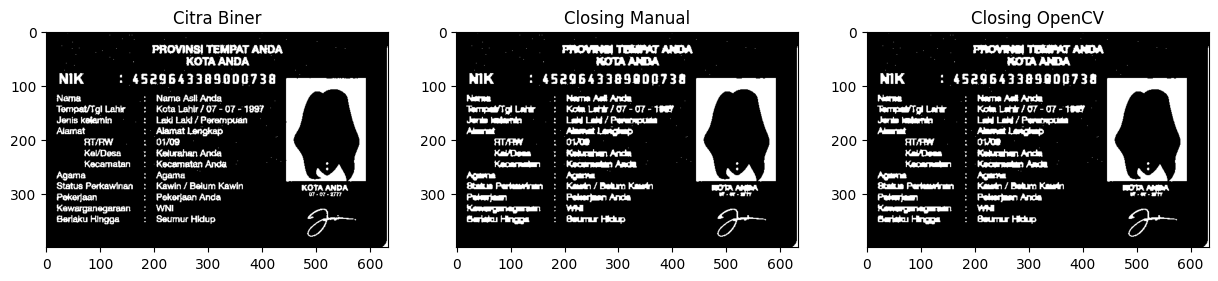

In [9]:
# Nomor 8. Closing Tanpa dan Dengan Library Morphology
SE = np.ones((3, 3), dtype=np.uint8)
closing_manual = erosi_citra(dilasi_citra(thresh, SE), SE)

kernel = np.ones((3, 3), dtype=np.uint8)
closing_lib = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(132), plt.imshow(closing_manual, cmap='gray'), plt.title('Closing Manual')
plt.subplot(133), plt.imshow(closing_lib, cmap='gray'), plt.title('Closing OpenCV')
plt.show()

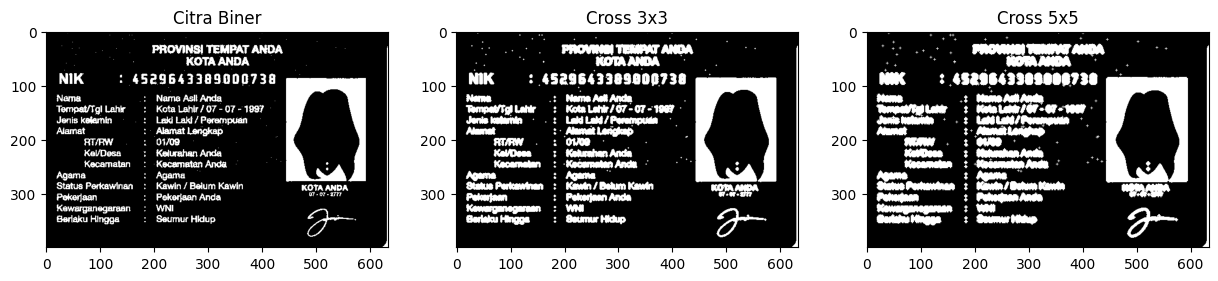

In [10]:
# Nomor 9. Dilasi Cross SED
cross3 = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
cross5 = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))

hasil_cross3 = cv2.dilate(thresh, cross3, iterations=1)
hasil_cross5 = cv2.dilate(thresh, cross5, iterations=1)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(132), plt.imshow(hasil_cross3, cmap='gray'), plt.title('Cross 3x3')
plt.subplot(133), plt.imshow(hasil_cross5, cmap='gray'), plt.title('Cross 5x5')
plt.show()

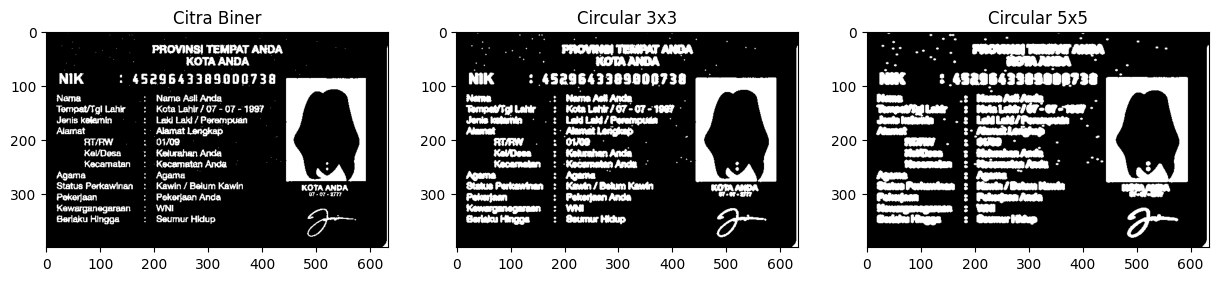

In [11]:
# Nomor 10. Dilasi Circular SED
circle3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
circle5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

hasil_circle3 = cv2.dilate(thresh, circle3, iterations=1)
hasil_circle5 = cv2.dilate(thresh, circle5, iterations=1)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(132), plt.imshow(hasil_circle3, cmap='gray'), plt.title('Circular 3x3')
plt.subplot(133), plt.imshow(hasil_circle5, cmap='gray'), plt.title('Circular 5x5')
plt.show()

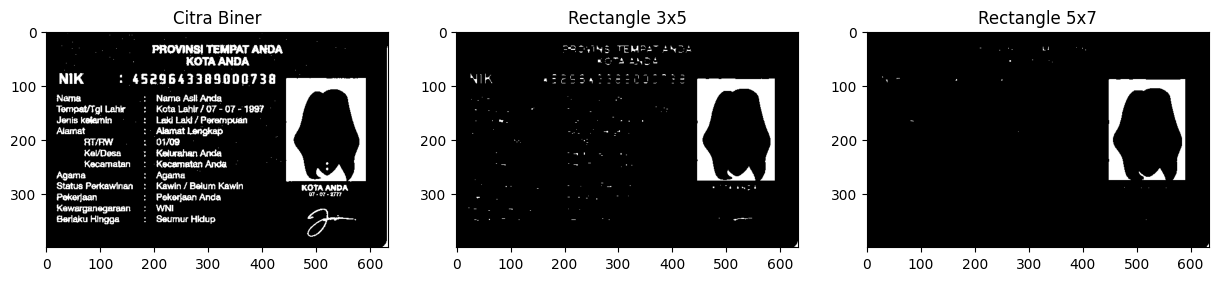

In [12]:
# Nomor 11. Erosi Rectangle SE
rect35 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 3))
rect57 = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 5))

hasil_rect35 = cv2.erode(thresh, rect35, iterations=1)
hasil_rect57 = cv2.erode(thresh, rect57, iterations=1)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(132), plt.imshow(hasil_rect35, cmap='gray'), plt.title('Rectangle 3x5')
plt.subplot(133), plt.imshow(hasil_rect57, cmap='gray'), plt.title('Rectangle 5x7')
plt.show()

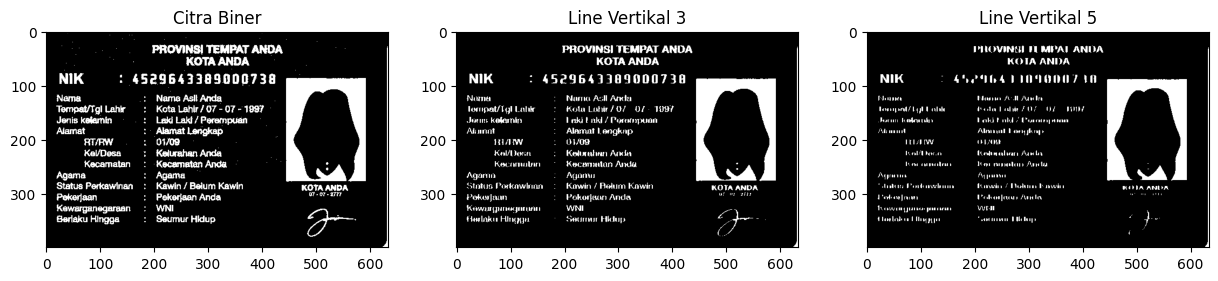

In [13]:
# Nomor 12. Erosi Line Vertikal SE
line3 = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3))
line5 = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 5))

hasil_line3 = cv2.erode(thresh, line3, iterations=1)
hasil_line5 = cv2.erode(thresh, line5, iterations=1)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner')
plt.subplot(132), plt.imshow(hasil_line3, cmap='gray'), plt.title('Line Vertikal 3')
plt.subplot(133), plt.imshow(hasil_line5, cmap='gray'), plt.title('Line Vertikal 5')
plt.show()

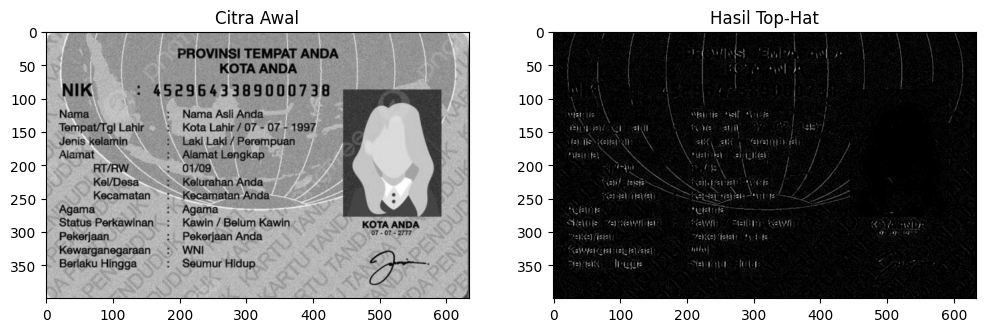

In [14]:
# Nomor 13. TopHat
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal')
plt.subplot(122), plt.imshow(tophat_img, cmap='gray'), plt.title('Hasil Top-Hat')
plt.show()

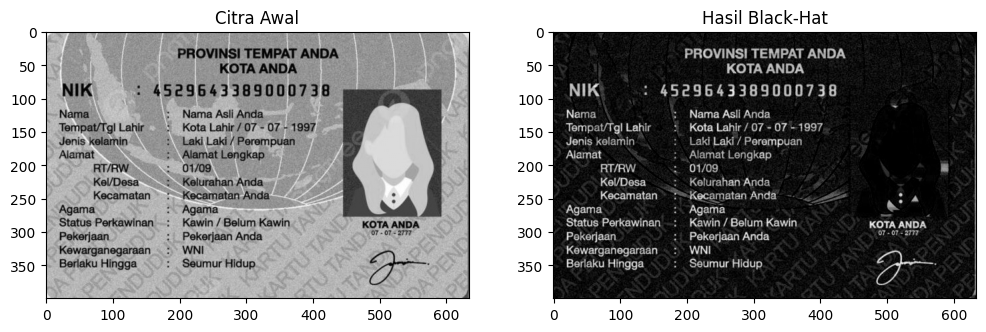

In [15]:
# Nomor 14. BlackHat
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat_img = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal')
plt.subplot(122), plt.imshow(blackhat_img, cmap='gray'), plt.title('Hasil Black-Hat')
plt.show()

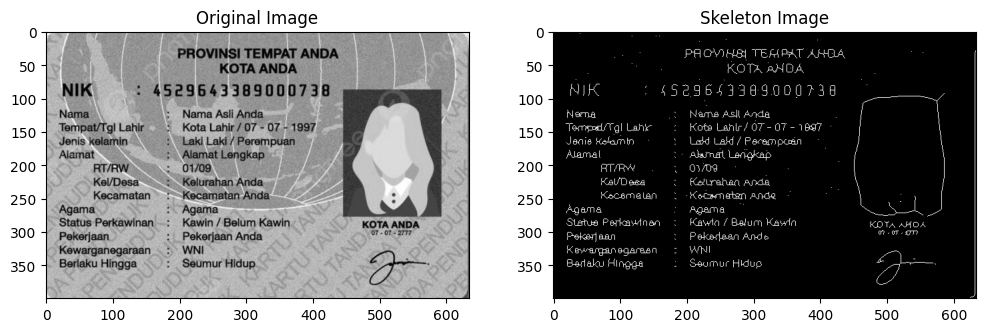

In [16]:
# Nomor 15. Skeleton
threshold_value = filters.threshold_triangle(img)
binary = img < threshold_value

skeleton = skeletonize(binary)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(122), plt.imshow(skeleton, cmap='gray'), plt.title('Skeleton Image')
plt.show()

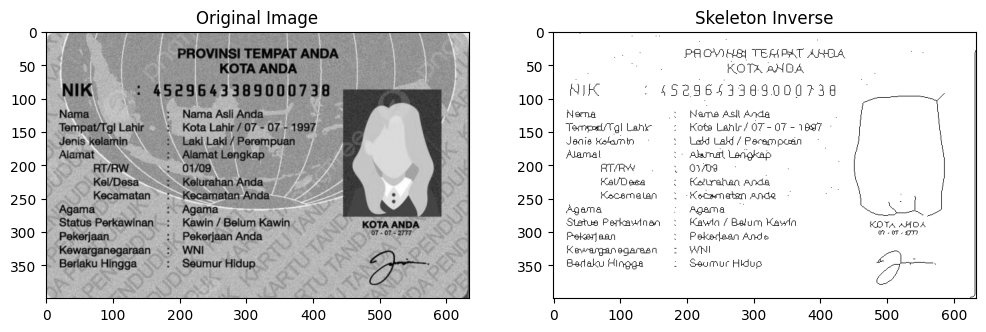

In [17]:
# Nomor 16. Skeleton Inverse
threshold_value = filters.threshold_triangle(img)
binary = img < threshold_value

skeleton = skeletonize(binary)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(122), plt.imshow(skeleton, cmap='gray_r'), plt.title('Skeleton Inverse')
plt.show()

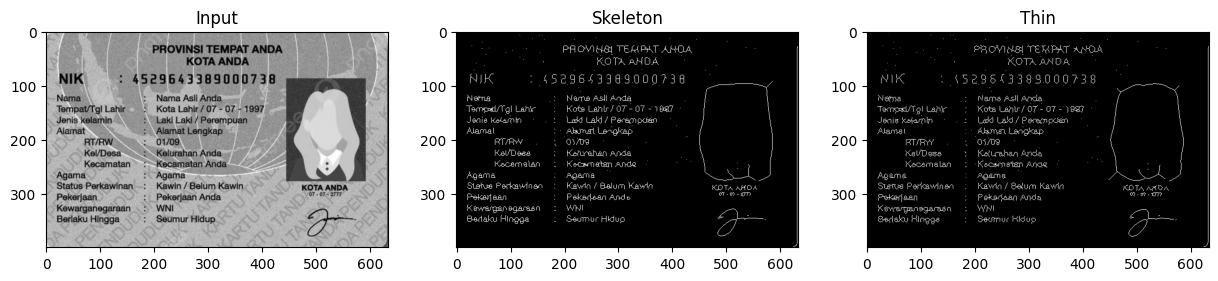

In [18]:
# Nomor 17. Thickening
image = img_as_float(img)
image_binary = image < 0.5

out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(image, cmap='gray'), plt.title('Input')
plt.subplot(132), plt.imshow(out_skeletonize, cmap='gray'), plt.title('Skeleton')
plt.subplot(133), plt.imshow(out_thin, cmap='gray'), plt.title('Thin')
plt.show()